In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os 
df = pd.read_csv("retail_sales.csv")

In [2]:
df

,order_id,date,region,product,quantity,unit_price
0,1001,2026-10-01,South,Laptop,2,55000
1,1002,2026-10-01,North,Mouse,10,500
2,1003,2026-10-02,South,Keyboard,5,1200
3,1004,2026-10-02,East,Laptop,1,55000
4,1005,2026-10-03,West,Monitor,3,12000
5,1006,2026-10-03,North,Mouse,15,500
6,1007,2026-10-04,South,Monitor,2,12000
7,1008,2026-10-04,East,Keyboard,8,1200
8,1009,2026-10-05,West,Laptop,1,55000
9,1010,2026-10-05,South,Mouse,20,500


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    10 non-null     int64
 1   date        10 non-null     str  
 2   region      10 non-null     str  
 3   product     10 non-null     str  
 4   quantity    10 non-null     int64
 5   unit_price  10 non-null     int64
dtypes: int64(3), str(3)
memory usage: 612.0 bytes


In [11]:
df.columns
len(df.columns)

6

In [12]:
df.isnull().sum()

order_id      0
date          0
region        0
product       0
quantity      0
unit_price    0
dtype: int64

In [14]:
df['total_sales'] = df['quantity'] * df['unit_price']
df

,order_id,date,region,product,quantity,unit_price,total_sales
0,1001,2026-10-01,South,Laptop,2,55000,110000
1,1002,2026-10-01,North,Mouse,10,500,5000
2,1003,2026-10-02,South,Keyboard,5,1200,6000
3,1004,2026-10-02,East,Laptop,1,55000,55000
4,1005,2026-10-03,West,Monitor,3,12000,36000
5,1006,2026-10-03,North,Mouse,15,500,7500
6,1007,2026-10-04,South,Monitor,2,12000,24000
7,1008,2026-10-04,East,Keyboard,8,1200,9600
8,1009,2026-10-05,West,Laptop,1,55000,55000
9,1010,2026-10-05,South,Mouse,20,500,10000


In [17]:
total_revenue = sum(df.total_sales)
print(f"total revenue: {total_revenue}")

total revenue: 318100


In [20]:
product_revenue = (df.groupby('product')['total_sales'].sum().sort_values(ascending=False))
product_revenue.head(3)

product
Laptop     220000
Monitor     60000
Mouse       22500
Name: total_sales, dtype: int64

In [21]:
regional_revenue = (df.groupby('region')['total_sales'].sum().sort_values(ascending=False))
regional_revenue

region
South    150000
West      91000
East      64600
North     12500
Name: total_sales, dtype: int64

In [22]:
daily_revenue = (df.groupby('date')['total_sales'].sum())
daily_revenue

date
2026-10-01    115000
2026-10-02     61000
2026-10-03     43500
2026-10-04     33600
2026-10-05     65000
Name: total_sales, dtype: int64

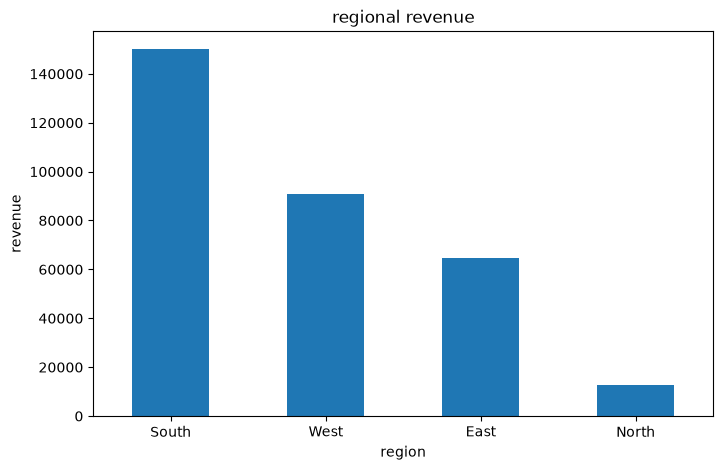

In [26]:
regional_revenue.plot(kind='bar',figsize=(8,5))
plt.title('regional revenue')
plt.xlabel('region')
plt.ylabel('revenue')
plt.xticks(rotation=0)
plt.show()

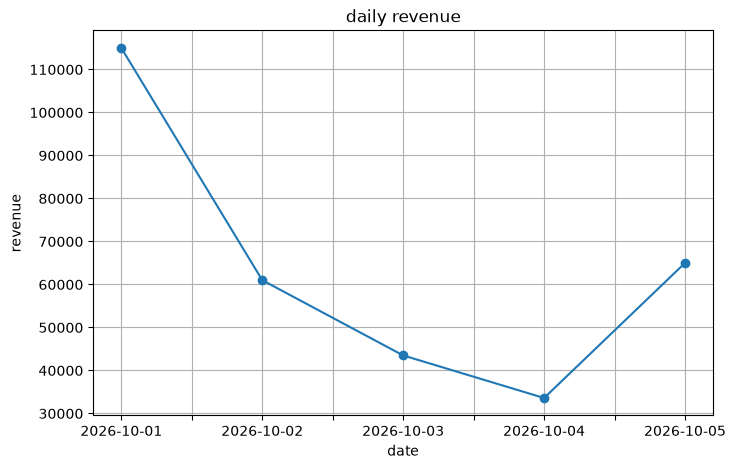

In [27]:
daily_revenue.plot(kind='line',figsize=(8,5),marker="o")
plt.title('daily revenue')
plt.xlabel('date')
plt.ylabel('revenue')
plt.grid(True)
plt.show()

In [30]:
best_product = product_revenue.idxmax()
best_product_revenue = product_revenue.max()
print(best_product)
print(best_product_revenue)

Laptop
220000


In [33]:
best_region = regional_revenue.idxmax()
best_region_revenue = regional_revenue.max()
print(best_region)
print(best_region_revenue)

South
150000
